# Упрощённый анализ факторов цены товара

В ноутбуке сравниваются три регрессионные модели с ценой одного конкурента в каждой, а затем оценивается расширенная модель со всеми тремя ценами. Вопрос: какие цены конкурентов связаны с общей ценой отдельно и сохраняется ли их связь при одновременном учёте? Результаты показывают статистические связи, но не доказывают причинное влияние.

В таблице 676 наблюдений по 52 товарам. Один товар встречается в разные месяцы, поэтому для проверки коэффициентов используются кластерные стандартные ошибки по `product_id`.

## 1. Подготовка данных

Для моделей нужны общая цена, число покупателей, цены трёх конкурентов, вес и идентификатор товара. `unit_price` и `qty` не включаются, поскольку их произведение приблизительно формирует `total_price`; `lag_price` почти совпадает с `unit_price`. Признак `s` исключён, так как его смысл описан неоднозначно. Все переменные, логарифмы которых рассчитываются, положительны.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

data = pd.read_csv(Path('retail_price.csv'))
columns = ['total_price', 'customers', 'comp_1', 'comp_2', 'comp_3', 'product_weight_g', 'product_id']
model_data = data[columns].dropna().copy()
numeric_columns = ['total_price', 'customers', 'comp_1', 'comp_2', 'comp_3', 'product_weight_g']
assert (model_data[numeric_columns] > 0).all().all()

for column in numeric_columns:
    model_data[f'log_{column}'] = np.log(model_data[column])

print(f'Наблюдений: {len(model_data)}')
print(f'Товарных групп: {model_data.product_id.nunique()}')
print(f'Строк с пропусками в выбранных переменных исключено: {len(data) - len(model_data)}')

Наблюдений: 676
Товарных групп: 52
Строк с пропусками в выбранных переменных исключено: 0


## 2. Краткое описание данных

Сначала посмотрим на среднее, медиану и диапазон исходных значений, затем сравним распределение цены до и после логарифмирования. Также проверим парные корреляции логарифмированных признаков; это описательная характеристика, а не полная диагностика мультиколлинеарности.

In [2]:
descriptive = model_data[numeric_columns].agg(['mean', 'median', 'min', 'max']).T
descriptive.index = ['Общая цена', 'Число покупателей', 'Цена конкурента 1', 'Цена конкурента 2', 'Цена конкурента 3', 'Вес товара, г']
descriptive.columns = ['Среднее', 'Медиана', 'Минимум', 'Максимум']
display(descriptive.round(2))

,Среднее,Медиана,Минимум,Максимум
Общая цена,1422.71,807.89,19.9,12095.00
Число покупателей,81.03,62.00,1.0,339.00
Цена конкурента 1,79.45,69.90,19.9,349.90
Цена конкурента 2,92.93,89.99,19.9,349.90
Цена конкурента 3,84.18,59.90,19.9,255.61
"Вес товара, г",1847.50,950.00,100.0,9750.00


### Распределение общей цены

Гистограммы показывают исходную цену и её натуральный логарифм. Логарифмирование сжимает большие значения; этот график помогает описать данные, но сам по себе не проверяет все предпосылки регрессии.

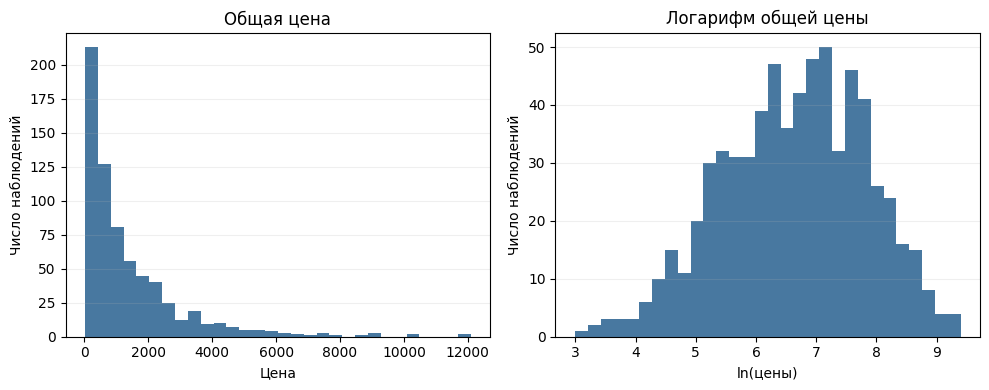

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(model_data['total_price'], bins=30, color='#286090', alpha=0.85)
axes[0].set_title('Общая цена')
axes[0].set_xlabel('Цена')
axes[0].set_ylabel('Число наблюдений')
axes[0].grid(axis='y', alpha=0.2)
axes[1].hist(model_data['log_total_price'], bins=30, color='#286090', alpha=0.85)
axes[1].set_title('Логарифм общей цены')
axes[1].set_xlabel('ln(цены)')
axes[1].set_ylabel('Число наблюдений')
axes[1].grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig('price_distribution_simple.png', dpi=160, bbox_inches='tight')
plt.show()

### Парные корреляции признаков

Матрица ниже показывает корреляции Пирсона между логарифмированными ценами трёх конкурентов. Корреляции описывают попарную связь и не являются полной проверкой мультиколлинеарности.

In [4]:
predictor_columns = ['log_comp_1', 'log_comp_2', 'log_comp_3']
correlation_matrix = model_data[predictor_columns].corr()
correlation_labels = ['Цена конкурента 1', 'Цена конкурента 2', 'Цена конкурента 3']
correlation_display = correlation_matrix.copy()
correlation_display.index = correlation_labels
correlation_display.columns = correlation_labels
display(correlation_display.round(4))
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
)
max_pairwise_correlation = upper_triangle.abs().max().max()
print(f'Максимальная парная корреляция по модулю: {max_pairwise_correlation:.4f}')

,Цена конкурента 1,Цена конкурента 2,Цена конкурента 3
Цена конкурента 1,1.0000,0.4358,0.5815
Цена конкурента 2,0.4358,1.0000,0.5117
Цена конкурента 3,0.5815,0.5117,1.0000


Максимальная парная корреляция по модулю: 0.5815


## 3. Оценка модели и статистические проверки

Сначала сравниваются три модели, в каждой из которых одна цена конкурента используется вместе с числом покупателей и весом. Затем оценивается модель `ln(total_price) ~ ln(customers) + ln(comp_1) + ln(comp_2) + ln(comp_3) + ln(product_weight_g)`. Для всех моделей применяются кластерные стандартные ошибки по товару. В расширенной модели отдельно проверяются индивидуальные коэффициенты, все коэффициенты модели и совместная гипотеза о нулевых коэффициентах трёх конкурентов. Уровень значимости — 5%.

In [5]:
product_groups = pd.factorize(model_data['product_id'])[0]
competitor_variables = ['comp_1', 'comp_2', 'comp_3']
candidate_rows = []
for competitor in competitor_variables:
    candidate_formula = (
        f'log_total_price ~ log_customers + log_{competitor} '
        '+ log_product_weight_g'
    )
    candidate_ols = smf.ols(candidate_formula, data=model_data).fit()
    candidate_cluster = candidate_ols.get_robustcov_results(
        cov_type='cluster', groups=product_groups, use_correction=True,
        df_correction=True, use_t=True,
    )
    coefficient_index = candidate_ols.model.exog_names.index(f'log_{competitor}')
    candidate_interval = candidate_cluster.conf_int(alpha=0.05)[coefficient_index]
    candidate_rows.append({
        'Конкурент': competitor,
        'Коэффициент': candidate_cluster.params[coefficient_index],
        'Кластерная SE': candidate_cluster.bse[coefficient_index],
        't': candidate_cluster.tvalues[coefficient_index],
        'p-value': candidate_cluster.pvalues[coefficient_index],
        '95%-ный интервал': f'[{candidate_interval[0]:.3f}; {candidate_interval[1]:.3f}]',
        'R²': candidate_ols.rsquared,
        'Скорректированный R²': candidate_ols.rsquared_adj,
    })
candidate_summary = pd.DataFrame(candidate_rows)
candidate_summary_display = candidate_summary.copy()
candidate_summary_display['p-value'] = candidate_summary['p-value'].map(lambda value: f'{value:.3g}')
display(candidate_summary_display.round({'Коэффициент': 4, 'Кластерная SE': 4, 't': 3, 'R²': 3, 'Скорректированный R²': 3}))

formula = (
    'log_total_price ~ log_customers + log_comp_1 + log_comp_2 '
    '+ log_comp_3 + log_product_weight_g'
)
ols_result = smf.ols(formula, data=model_data).fit()
cluster_result = ols_result.get_robustcov_results(
    cov_type='cluster', groups=product_groups, use_correction=True,
    df_correction=True, use_t=True,
)
confidence_intervals = cluster_result.conf_int(alpha=0.05)
results = pd.DataFrame({
    'Коэффициент': cluster_result.params,
    'Кластерная SE': cluster_result.bse,
    't': cluster_result.tvalues,
    'p-value': cluster_result.pvalues,
    'Нижняя граница 95%': confidence_intervals[:, 0],
    'Верхняя граница 95%': confidence_intervals[:, 1],
}, index=ols_result.model.exog_names)
result_order = ['log_customers', 'log_comp_1', 'log_comp_2', 'log_comp_3', 'log_product_weight_g']
result_labels = ['Число покупателей', 'Цена конкурента 1', 'Цена конкурента 2', 'Цена конкурента 3', 'Вес товара']
results_display = results.loc[result_order].copy()
results_display.index = result_labels
results_display = results_display.round(4)
results_display['p-value'] = results.loc[result_order, 'p-value'].map(lambda value: f'{value:.3g}').to_numpy()
display(results_display)

competitor_restriction = np.zeros((3, len(cluster_result.params)))
competitor_restriction[:, 2:5] = np.eye(3)
competitor_test = cluster_result.f_test(competitor_restriction)
model_restriction = np.zeros((5, len(cluster_result.params)))
model_restriction[:, 1:] = np.eye(5)
model_test = cluster_result.f_test(model_restriction)
denominator_df = model_data.product_id.nunique() - 1
print(
    f'Совместный тест цен конкурентов: F(3, {denominator_df}) = '
    f'{float(np.asarray(competitor_test.fvalue).squeeze()):.2f}, '
    f'p-value = {float(np.asarray(competitor_test.pvalue).squeeze()):.3g}'
)
print(
    f'Тест модели в целом: F(5, {denominator_df}) = '
    f'{float(np.asarray(model_test.fvalue).squeeze()):.2f}, '
    f'p-value = {float(np.asarray(model_test.pvalue).squeeze()):.3g}'
)
print(f'R²: {ols_result.rsquared:.3f}')
print(f'Скорректированный R²: {ols_result.rsquared_adj:.3f}')
print(f'Число степеней свободы для кластерного t-критерия: {denominator_df}')

,Конкурент,Коэффициент,Кластерная SE,t,p-value,95%-ный интервал,R²,Скорректированный R²
0,comp_1,0.3637,0.1420,2.562,0.0134,[0.079; 0.649],0.239,0.236
1,comp_2,0.6687,0.1454,4.600,2.83e-05,[0.377; 0.961],0.289,0.286
2,comp_3,0.5260,0.1410,3.731,0.00048,[0.243; 0.809],0.257,0.254


,Коэффициент,Кластерная SE,t,p-value,Нижняя граница 95%,Верхняя граница 95%
Число покупателей,0.5431,0.0573,9.4715,7.94e-13,0.4280,0.6582
Цена конкурента 1,0.0350,0.1393,0.2515,0.802,-0.2447,0.3147
Цена конкурента 2,0.5323,0.2028,2.6242,0.0114,0.1251,0.9395
Цена конкурента 3,0.2281,0.1972,1.1569,0.253,-0.1677,0.6239
Вес товара,0.1350,0.0631,2.1394,0.0372,0.0083,0.2617


Совместный тест цен конкурентов: F(3, 51) = 10.58, p-value = 1.61e-05
Тест модели в целом: F(5, 51) = 28.73, p-value = 9.87e-14
R²: 0.298
Скорректированный R²: 0.293
Число степеней свободы для кластерного t-критерия: 51


### Сравнение спецификаций и расширенная модель

В трёх отдельных моделях каждая цена конкурента положительно связана с общей ценой и значима при 5%. Наибольший скорректированный `R²` у модели с `comp_2` — 0,286; сравнение относится только к этой выборке.

В расширенной модели все три цены включены одновременно. `comp_2` сохраняет положительную индивидуальную связь (`β = 0,532`, `p = 0,011`); для `comp_1` (`p = 0,802`) и `comp_3` (`p = 0,253`) индивидуальная значимость не подтверждена. Совместный тест цен конкурентов значим: `F(3, 51) = 10,58`, `p < 0,001`.

Число покупателей (`β = 0,543`, `p < 0,001`) и вес товара (`β = 0,135`, `p = 0,037`) также значимы в расширенной модели. Её `R² = 0,298`, скорректированный `R² = 0,293`. Интерпретация коэффициентов условная и не доказывает причинного влияния.

In [6]:
effect_labels = ['Число покупателей', 'Цена конкурента 1', 'Цена конкурента 2', 'Цена конкурента 3', 'Вес товара']
effect_coefficients = cluster_result.params[1:]
effect_pvalues = cluster_result.pvalues[1:]
effect_values = (np.power(1.10, effect_coefficients) - 1) * 100
effect_table = pd.DataFrame({
    'Признак': effect_labels,
    'Модельная оценка изменения при росте на 10%, %': effect_values,
    'p-value': [f'{value:.3g}' for value in effect_pvalues],
    'Значима при 5%': np.where(effect_pvalues < 0.05, 'Да', 'Нет'),
})
display(effect_table.round(2))

,Признак,"Модельная оценка изменения при росте на 10%, %",p-value,Значима при 5%
0,Число покупателей,5.31,7.94e-13,Да
1,Цена конкурента 1,0.33,0.802,Нет
2,Цена конкурента 2,5.20,0.0114,Да
3,Цена конкурента 3,2.20,0.253,Нет
4,Вес товара,1.30,0.0372,Да


## 4. Графики коэффициентов и остатков

Первый график показывает оценки коэффициентов и их 95%-ные кластерные интервалы; вертикальная линия отмечает ноль. Второй показывает остатки и предсказанные значения. Это визуальные проверки, а не формальные тесты всех предпосылок.

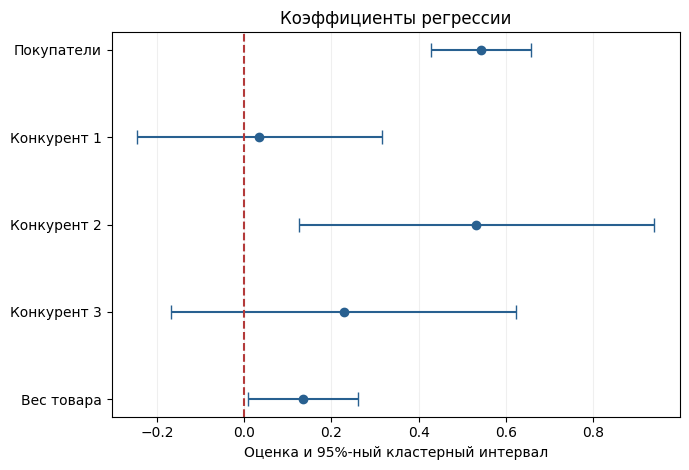

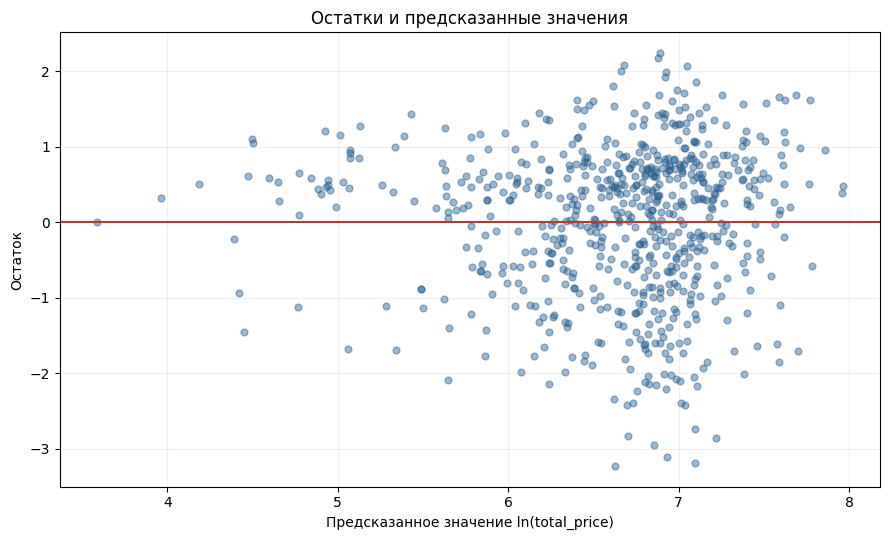

In [7]:
coefficient_labels = ['Покупатели', 'Конкурент 1', 'Конкурент 2', 'Конкурент 3', 'Вес товара']
coefficient_values = cluster_result.params[1:]
coefficient_intervals = confidence_intervals[1:]
positions = np.arange(len(coefficient_values))
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.errorbar(
    coefficient_values,
    positions,
    xerr=np.vstack([
        coefficient_values - coefficient_intervals[:, 0],
        coefficient_intervals[:, 1] - coefficient_values,
    ]),
    fmt='o',
    capsize=5,
    color='#286090',
    ecolor='#286090',
)
ax.axvline(0, color='#b33a3a', linestyle='--', linewidth=1.5)
ax.set_yticks(positions, labels=coefficient_labels)
ax.invert_yaxis()
ax.set_xlabel('Оценка и 95%-ный кластерный интервал')
ax.set_title('Коэффициенты регрессии')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig('coefficients_ci_simple.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(ols_result.fittedvalues, ols_result.resid, alpha=0.45, color='#286090', s=24)
ax.axhline(0, color='#b33a3a', linewidth=1.5)
ax.set_title('Остатки и предсказанные значения')
ax.set_xlabel('Предсказанное значение ln(total_price)')
ax.set_ylabel('Остаток')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig('residuals_simple.png', dpi=160, bbox_inches='tight')
plt.show()